# Học Hiểu 100% Thuật Toán **G³-VPR v3** Từ 1 Bức Ảnh Thật (Cell-by-Cell)

Notebook này cho **1 bức ảnh đường phố thật** (`SPED`) đi qua từng tầng một của mô hình **`G³-VPR v3` đã huấn luyện xong** (`g3vpr_universal_best.pth`), in ra **từng con số thật** và **vẽ từng ảnh trung gian thật** ở cả **5 tầng**:
1. **Cell 1:** Nạp mô hình thật + 3 ảnh thật (**Query**, **Positive cùng địa điểm**, **Hard Negative đen trắng**).
2. **Cell 2 — Tầng 1 (`Geo-Semantic Backbone + 3D Head`):** Xem bản đồ độ sâu **`Pseudo-Depth`** và mặt nạ bỏ trời/xe **`Salience Gate`** do mạng tự đoán.
3. **Cell 3 — Tầng 2 (`3D-DGSA`):** Vẽ **16 hình elip Gaussian xoay thật** bám lên tòa nhà + xem bảng số $(\mu_x, \mu_y, \sigma_x, \sigma_y, 	heta, ar{d}_k, ar{s}_k)$.
4. **Cell 4 — Tầng 3 (`Nyström-PMCI`):** Kiểm chứng trực tiếp độ bất biến **`BS=1` vs `BS=8`** (sai số $\sim 10^{-7}$) + xem phân bố sử dụng 128 nguyên mẫu.
5. **Cell 5 — Tầng 4 (`Matryoshka Head`):** Đo điểm Cosine Similarity thật trên cả **6 cỡ `128 / 256 / 512 / 1024 / 2048 / 4096-D`** cho cặp Đúng vs cặp Sai.
6. **Cell 6 — Tầng 5 (`G-OTR` Xác minh Hình học 3D):** Dựng tọa độ 3D $p_k \in \mathbb{R}^3$, vẽ **ma trận vận chuyển tối ưu Sinkhorn `16×16` thật ($T^*$)** và tính điểm 3D Gromov-Wasserstein!
7. **Cell 7 — Tầng 5b (`AM-VPR Conformal Cascade`):** Mô phỏng quyết định thoát sớm ở `128-D` dựa trên `Margin = Top1 - Top2`.


[OK] Da nap G3-VPR v3 tren cuda | Tong tham so: 36.0721M
Kich thuoc Tensor dau vao Query (BS=1): (1, 3, 224, 224) | min/max sau chuan hoa: -2.07 / 2.52


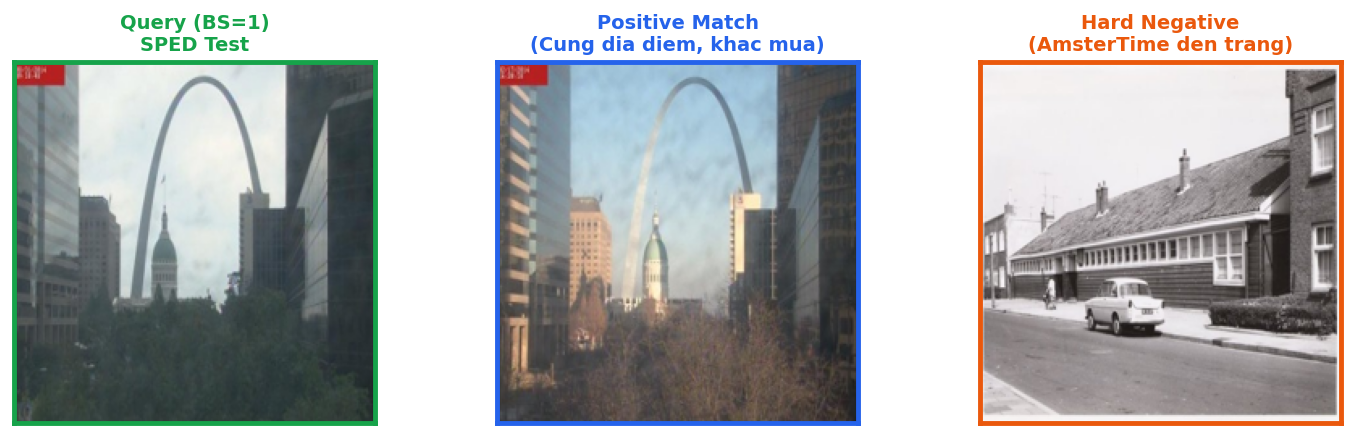

In [1]:
# Cell 1: Nap mo hinh G3-VPR v3 da train & 3 anh that (Query, Positive, Hard Negative)
import os, time
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from g3vpr import build_g3vpr, pack_gaussian_primitives
from g3vpr.gotr_reranker import compute_gotr_pair_scores, sinkhorn_log_domain, bures_wasserstein_2x2_sq
from src.dataloaders.gsv_cities import build_eval_transform

device = "cuda" if torch.cuda.is_available() else "cpu"
ckpt_path = "./g3vpr_paper_artifacts_v3/checkpoints/g3vpr_M5_full/g3vpr_universal_best.pth"
if not os.path.isfile(ckpt_path):
    ckpt_path = "./g3vpr_paper_artifacts_v3/checkpoints/g3vpr_M5_full/g3vpr_best_fp16.pth"

model = build_g3vpr(ablation="M5_full").to(device)
ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state_dict"], strict=True)
model.eval()
print(f"[OK] Da nap G3-VPR v3 tren {device} | Tong tham so: {model.parameter_breakdown()['total_M']}M")

# Chon 3 anh that: Query (SPED), Positive (cung dia diem SPED), Hard Negative (AmsterTime den trang)
q_path = "./datasets/sped/images/test/queries/@0@0@@@@@0000000@@@@@@@@.jpg"
p_path = "./datasets/sped/images/test/database/@0@0@@@@@0000000@@@@@@@@.jpg"
n_path = "./datasets/amstertime/images/test/queries/@0@0@@@@@0000@@@@@@@@.jpg"

tf = build_eval_transform(224)
img_q_pil = Image.open(q_path).convert("RGB").resize((224, 224))
img_p_pil = Image.open(p_path).convert("RGB").resize((224, 224))
img_n_pil = Image.open(n_path).convert("RGB").resize((224, 224))

x_q = tf(img_q_pil).unsqueeze(0).to(device)  # [1, 3, 224, 224] -> STRICT BS=1!
x_p = tf(img_p_pil).unsqueeze(0).to(device)
x_n = tf(img_n_pil).unsqueeze(0).to(device)

print("Kich thuoc Tensor dau vao Query (BS=1):", tuple(x_q.shape),
      "| min/max sau chuan hoa:", round(x_q.min().item(), 2), "/", round(x_q.max().item(), 2))

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.2))
for ax, im, title, col in zip(
    axes,
    [img_q_pil, img_p_pil, img_n_pil],
    ["Query (BS=1)\nSPED Test", "Positive Match\n(Cung dia diem, khac mua)", "Hard Negative\n(AmsterTime den trang)"],
    ["#16A34A", "#2563EB", "#EA580C"],
):
    ax.imshow(im)
    ax.set_title(title, fontsize=10, fontweight="bold", color=col)
    for sp in ax.spines.values():
        sp.set_edgecolor(col); sp.set_linewidth(2.5)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


1. patch_map shape   : (1, 512, 16, 16) (luoi 16x16 o anh, moi o 512 dac trung)
2. cls_token shape   : (1, 512)
3. pseudo_depth      : shape=(1, 1, 16, 16) | min=0.036, max=0.673
4. salience_gate     : shape=(1, 1, 16, 16) | min=0.053, max=0.446 (gan 1 = cong trinh, gan 0 = troi/xe)


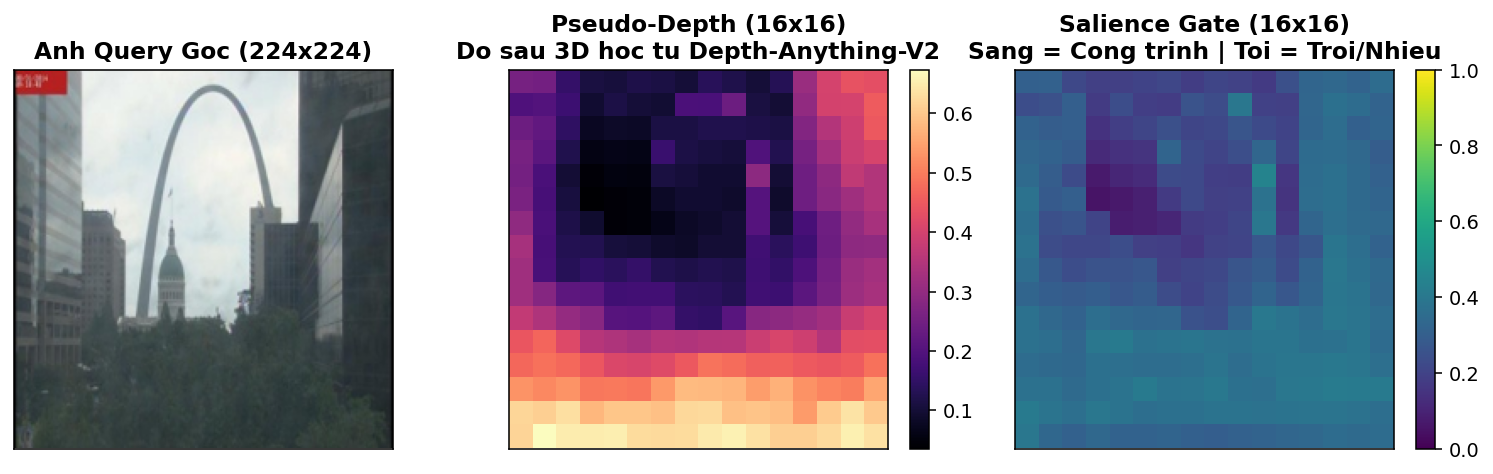

In [2]:
# Cell 2 — TANG 1: Geo-Semantic Backbone (DINOv2-S + Gated-DRM + 3D Head)
with torch.no_grad():
    bb_q = model.backbone(x_q)

patch_map = bb_q["patch_map"]          # [1, 512, 16, 16]
cls_token = bb_q["cls_token"]          # [1, 512]
pseudo_depth = bb_q["pseudo_depth"]    # [1, 1, 16, 16]
salience = bb_q["salience_gate"]       # [1, 1, 16, 16]

print("1. patch_map shape   :", tuple(patch_map.shape), "(luoi 16x16 o anh, moi o 512 dac trung)")
print("2. cls_token shape   :", tuple(cls_token.shape))
print(f"3. pseudo_depth      : shape={tuple(pseudo_depth.shape)} | min={pseudo_depth.min().item():.3f}, max={pseudo_depth.max().item():.3f}")
print(f"4. salience_gate     : shape={tuple(salience.shape)} | min={salience.min().item():.3f}, max={salience.max().item():.3f} (gan 1 = cong trinh, gan 0 = troi/xe)")

depth_2d = pseudo_depth[0, 0].cpu().numpy()
sal_2d = salience[0, 0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.3))
axes[0].imshow(img_q_pil); axes[0].set_title("Anh Query Goc (224x224)", fontweight="bold")
im1 = axes[1].imshow(depth_2d, cmap="magma"); axes[1].set_title("Pseudo-Depth (16x16)\nDo sau 3D hoc tu Depth-Anything-V2", fontweight="bold")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
im2 = axes[2].imshow(sal_2d, cmap="viridis", vmin=0, vmax=1); axes[2].set_title("Salience Gate (16x16)\nSang = Cong trinh | Toi = Troi/Nhieu", fontweight="bold")
plt.colorbar(im2, ax=axes[2], fraction=0.046)
for a in axes: a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.show()


Output tokens shape: (1, 17, 512) (= 1 Global token + 16 Splat tokens, moi token 512-D)

Bang thong so 5 hinh Elip Gaussian dau tien (so thuc tu model):
Elip |   Tam (ux, uy) |    Co (sx, sy) | Xoay (deg) | Do sau d_k | Salience s_k
------------------------------------------------------------------------------
 # 1 | (0.175, 0.139) | (0.238, 0.203) |    -13.97° |      0.226 |        0.242
 # 2 | (0.878, 0.076) | (0.244, 0.258) |    -30.14° |      0.399 |        0.305
 # 3 | (0.145, 0.903) | (0.225, 0.177) |     -6.47° |      0.729 |        0.356
 # 4 | (0.742, 0.916) | (0.229, 0.173) |     -7.07° |      0.749 |        0.367
 # 5 | (0.133, 0.073) | (0.157, 0.130) |     -5.13° |      0.239 |        0.249


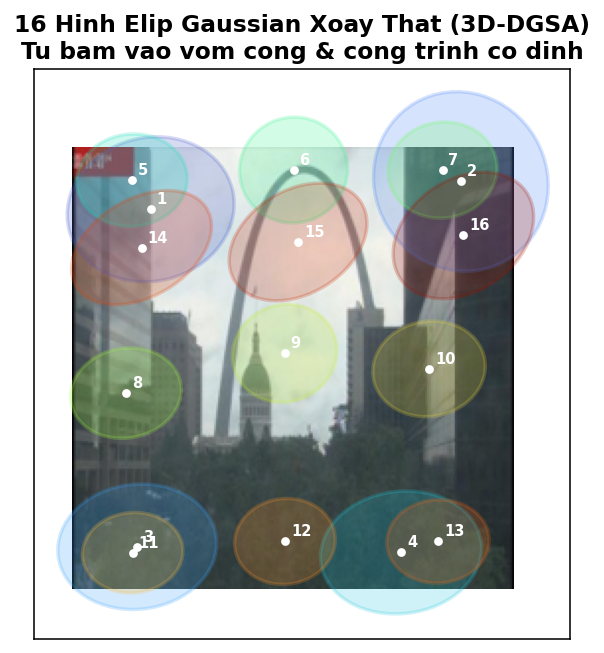

In [3]:
# Cell 3 — TANG 2: 3D-DGSA (16 Hinh Elip Gaussian Xoay + Symmetric Signed GeM)
with torch.no_grad():
    agg_q = model.aggregator(patch_map, cls_token, salience, pseudo_depth)

mu = agg_q["mu"][0].cpu().numpy()              # [16, 2] trong [0, 1]
sigma = agg_q["sigma"][0].cpu().numpy()        # [16, 2] ban truc
theta = agg_q["theta"][0].cpu().numpy()        # [16] goc xoay (radian)
m_depth = agg_q["mean_depth"][0, :, 0].cpu().numpy()
m_sal = agg_q["mean_sal"][0, :, 0].cpu().numpy()

print("Output tokens shape:", tuple(agg_q["tokens"].shape), "(= 1 Global token + 16 Splat tokens, moi token 512-D)")
print("\nBang thong so 5 hinh Elip Gaussian dau tien (so thuc tu model):")
print(f"{'Elip':>4} | {'Tam (ux, uy)':>14} | {'Co (sx, sy)':>14} | {'Xoay (deg)':>10} | {'Do sau d_k':>10} | {'Salience s_k':>12}")
print("-" * 78)
for k in range(5):
    print(f" #{k+1:2d} | ({mu[k,0]:.3f}, {mu[k,1]:.3f}) | ({sigma[k,0]:.3f}, {sigma[k,1]:.3f}) | {np.rad2deg(theta[k]):+9.2f}° | {m_depth[k]:10.3f} | {m_sal[k]:12.3f}")

# Ve 16 hinh elip Gaussian xoay that phu len anh Query!
fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax.imshow(img_q_pil)
cmap = plt.cm.turbo(np.linspace(0.1, 0.95, 16))
for k in range(16):
    cx, cy = mu[k, 0] * 224.0, mu[k, 1] * 224.0
    w, h = sigma[k, 0] * 224.0 * 1.6, sigma[k, 1] * 224.0 * 1.6
    deg = np.rad2deg(theta[k])
    el = Ellipse((cx, cy), width=w, height=h, angle=deg, facecolor=cmap[k], alpha=0.22, edgecolor=cmap[k], lw=1.8)
    ax.add_patch(el)
    ax.plot(cx, cy, "o", color="white", markersize=3.5)
    ax.text(cx + 3, cy - 3, str(k + 1), color="white", fontsize=7.5, fontweight="bold")
ax.set_title("16 Hinh Elip Gaussian Xoay That (3D-DGSA)\nTu bam vao vom cong & cong trinh co dinh", fontweight="bold")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


Kiem chung BS=1 vs BS=8:
  - Sai so tuyet doi lon nhat (max_abs_diff) = 1.03e-07
  - Do tuong dong Cosine (BS=1 vs BS=8)      = 1.00000000  (1.00000000 = bat bien tuyet doi!)
  - Top-5 nguyen mau (trong 128) duoc kich hoat manh nhat cho anh nay: [15, 18, 55, 65, 127]


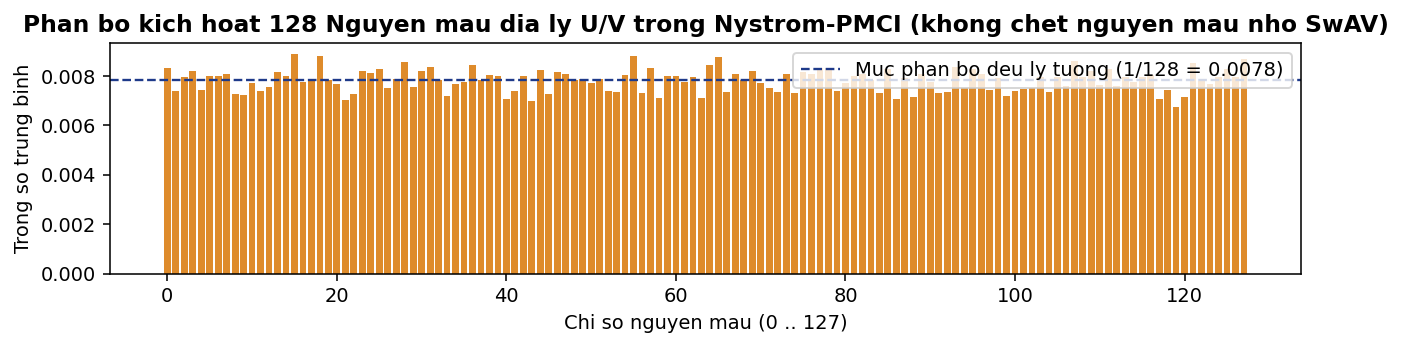

In [4]:
# Cell 4 — TANG 3: Nystrom-PMCI (Tay nhieu mien & Kiem chung Bat bien tuyet doi BS=1)
with torch.no_grad():
    pmci_q = model.pmci(agg_q["tokens"])
    assign = pmci_q["proto_assign"][0].cpu().numpy()  # [17, 128]

    # Kiem chung BS=1 vs BS=8 (ghep Query cung 7 anh ngau nhien khac!)
    batch8 = torch.cat([x_q, x_p, x_n, torch.randn(5, 3, 224, 224, device=device)], dim=0)
    desc_bs1 = model(x_q, output_dim=4096)
    desc_bs8 = model(batch8, output_dim=4096)[0:1]
    max_diff = (desc_bs1 - desc_bs8).abs().max().item()
    cos_bs = F.cosine_similarity(desc_bs1, desc_bs8).item()

print(f"Kiem chung BS=1 vs BS=8:")
print(f"  - Sai so tuyet doi lon nhat (max_abs_diff) = {max_diff:.2e}")
print(f"  - Do tuong dong Cosine (BS=1 vs BS=8)      = {cos_bs:.8f}  (1.00000000 = bat bien tuyet doi!)")

# Ve bieu do phan bo gan 128 Nguyen mau (Prototypes)
proto_usage = assign.mean(axis=0)  # trung binh tren 17 token
top5_p = np.argsort(proto_usage)[::-1][:5]
print("  - Top-5 nguyen mau (trong 128) duoc kich hoat manh nhat cho anh nay:", top5_p.tolist())

fig, ax = plt.subplots(figsize=(9.5, 2.6))
ax.bar(np.arange(128), proto_usage, color="#D97706", alpha=0.85, width=0.8)
ax.axhline(1.0 / 128.0, color="#1E3A8A", ls="--", lw=1.2, label="Muc phan bo deu ly tuong (1/128 = 0.0078)")
ax.set_title("Phan bo kich hoat 128 Nguyen mau dia ly U/V trong Nystrom-PMCI (khong chet nguyen mau nho SwAV)", fontweight="bold")
ax.set_xlabel("Chi so nguyen mau (0 .. 127)"); ax.set_ylabel("Trong so trung binh")
ax.legend()
plt.tight_layout()
plt.show()


8 so dau tien cua vector Query 4096-D: [-0.0414000004529953, 0.0006000000284984708, 0.007400000002235174, -0.023600000888109207, 0.011900000274181366, -0.017500000074505806, 0.002199999988079071, 0.01810000091791153]

So sanh diem Cosine Similarity THAT tren 6 co Matryoshka (cang gan 1 cang giong):
  So chieu | RAM 1M anh |  Query vs Positive (DUNG) |  Query vs Negative (SAI) | Khoang cach (Margin)
--------------------------------------------------------------------------------------------------
     128-D |    0.48 GB |                    0.8828 |                   0.1443 |              +0.7385
     256-D |    0.95 GB |                    0.8658 |                   0.0684 |              +0.7974
     512-D |    1.91 GB |                    0.8662 |                   0.0312 |              +0.8351
    1024-D |    3.81 GB |                    0.8676 |                   0.0597 |              +0.8079
    2048-D |    7.63 GB |                    0.8913 |                   0.1850 |           

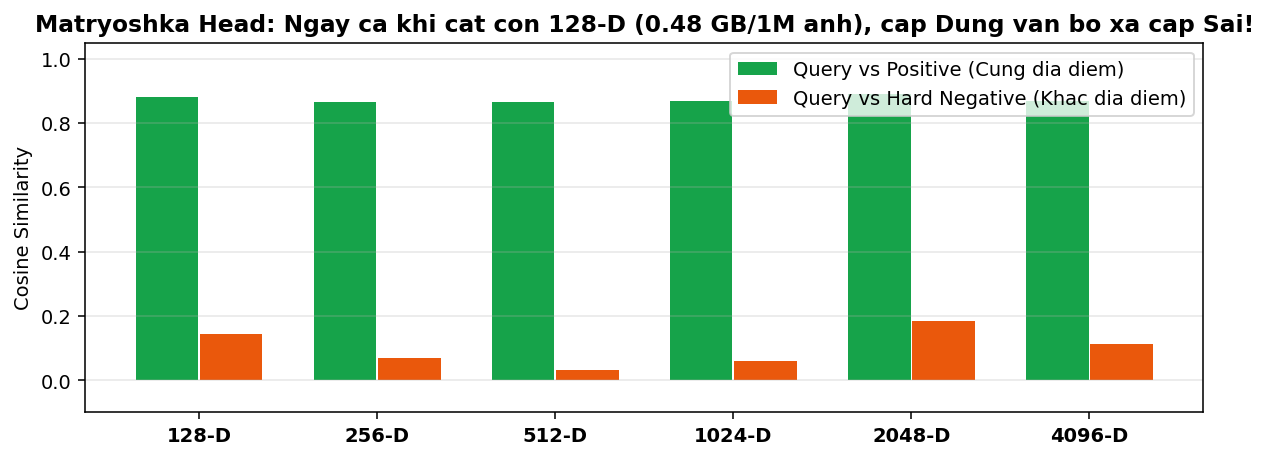

In [5]:
# Cell 5 — TANG 4: Orthogonal Matryoshka Head (128 -> 4096-D) & Do Cosine That
with torch.no_grad():
    out_q = model(x_q, return_aux=True)
    out_p = model(x_p, return_aux=True)
    out_n = model(x_n, return_aux=True)

dims = [128, 256, 512, 1024, 2048, 4096]
sim_pos, sim_neg = [], []

print("8 so dau tien cua vector Query 4096-D:", np.round(out_q["descriptor"][0, :8].cpu().numpy(), 4).tolist())
print("\nSo sanh diem Cosine Similarity THAT tren 6 co Matryoshka (cang gan 1 cang giong):")
print(f"{'So chieu':>10} | {'RAM 1M anh':>10} | {'Query vs Positive (DUNG)':>25} | {'Query vs Negative (SAI)':>24} | {'Khoang cach (Margin)':>20}")
print("-" * 98)
for d in dims:
    vq = out_q["nested_descriptors"][d]
    vp = out_p["nested_descriptors"][d]
    vn = out_n["nested_descriptors"][d]
    sp = float((vq * vp).sum().item())
    sn = float((vq * vn).sum().item())
    sim_pos.append(sp); sim_neg.append(sn)
    ram_gb = (1_000_000 * d * 4) / (1024 ** 3)
    print(f"{d:>8}-D | {ram_gb:>7.2f} GB | {sp:>25.4f} | {sn:>24.4f} | {sp - sn:>+20.4f}")

fig, ax = plt.subplots(figsize=(8.8, 3.4))
x_idx = np.arange(len(dims))
ax.bar(x_idx - 0.18, sim_pos, width=0.35, color="#16A34A", label="Query vs Positive (Cung dia diem)")
ax.bar(x_idx + 0.18, sim_neg, width=0.35, color="#EA580C", label="Query vs Hard Negative (Khac dia diem)")
ax.set_xticks(x_idx); ax.set_xticklabels([f"{d}-D" for d in dims], fontweight="bold")
ax.set_ylabel("Cosine Similarity"); ax.set_ylim(-0.1, 1.05)
ax.set_title("Matryoshka Head: Ngay ca khi cat con 128-D (0.48 GB/1M anh), cap Dung van bo xa cap Sai!", fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


Toa do gia-3D p_k = d_k * [2*ux-1, 2*uy-1, 1] cua 3 elip dau tien trong Query:
  Elip #1: p3d = (-0.147, -0.163, +0.226) | trong so salience pi_k = 0.0501
  Elip #2: p3d = (+0.302, -0.339, +0.399) | trong so salience pi_k = 0.0631
  Elip #3: p3d = (-0.518, +0.587, +0.729) | trong so salience pi_k = 0.0737

Ket qua xac minh hinh hoc 3D G-OTR (thoi gian ~82.42 ms/cap, 0 FLOPs backbone them):
  - Cap DUNG (Query vs Pos): Global=0.8695 | OT=0.8194 | 3D-GW=0.6591  ==> TONG = 0.8254
  - Cap SAI  (Query vs Neg): Global=0.1136 | OT=-0.0082 | 3D-GW=0.2800  ==> TONG = 0.1081


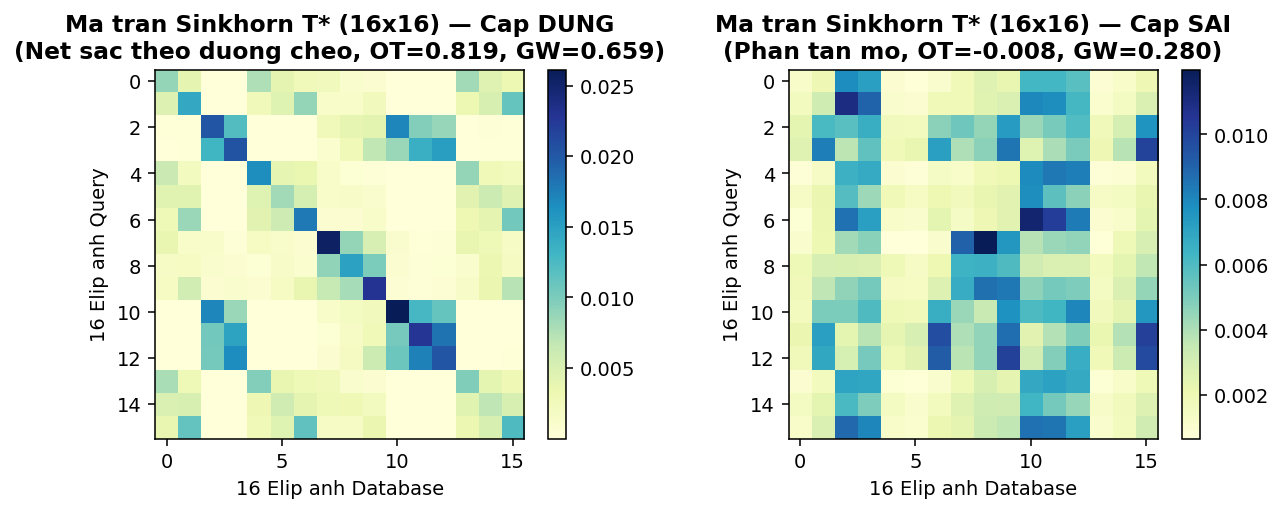

In [6]:
# Cell 6 — TANG 5: G-OTR (Xac minh Hinh hoc 3D Zero-Cost: Bures-Wasserstein + Sinkhorn + 3D GW)
with torch.no_grad():
    pq = pack_gaussian_primitives(out_q, feat_dim_keep=128)
    pp = pack_gaussian_primitives(out_p, feat_dim_keep=128)
    pn = pack_gaussian_primitives(out_n, feat_dim_keep=128)

    print("Toa do gia-3D p_k = d_k * [2*ux-1, 2*uy-1, 1] cua 3 elip dau tien trong Query:")
    for k in range(3):
        p3 = pq["p3d"][0, k].cpu().numpy()
        print(f"  Elip #{k+1}: p3d = ({p3[0]:+.3f}, {p3[1]:+.3f}, {p3[2]:+.3f}) | trong so salience pi_k = {pq['pi'][0, k].item():.4f}")

    # Tinh diem G-OTR + do thoi gian thuc
    t0 = time.perf_counter()
    ot_pos, gw_pos = compute_gotr_pair_scores(pq["feats"], pq["cov"], pq["p3d"], pq["pi"],
                                              pp["feats"], pp["cov"], pp["p3d"], pp["pi"])
    ot_neg, gw_neg = compute_gotr_pair_scores(pq["feats"], pq["cov"], pq["p3d"], pq["pi"],
                                              pn["feats"], pn["cov"], pn["p3d"], pn["pi"])
    ms_pair = (time.perf_counter() - t0) * 1000.0 / 2.0

    # Tinh ma tran van chuyen toi uu T* (16x16) de ve truc quan!
    def get_plan(a, b):
        sim = torch.bmm(a["feats"], b["feats"].transpose(1, 2))
        w2 = bures_wasserstein_2x2_sq(a["cov"], b["cov"])
        cost = (1.0 - sim) + 1.5 * w2
        return sinkhorn_log_domain(cost, a["pi"], b["pi"])[0].cpu().numpy()

    T_pos = get_plan(pq, pp)
    T_neg = get_plan(pq, pn)

g_pos = sim_pos[-1]
g_neg = sim_neg[-1]
final_pos = 0.60 * g_pos + 0.25 * ot_pos.item() + 0.15 * gw_pos.item()
final_neg = 0.60 * g_neg + 0.25 * ot_neg.item() + 0.15 * gw_neg.item()

print(f"\nKet qua xac minh hinh hoc 3D G-OTR (thoi gian ~{ms_pair:.2f} ms/cap, 0 FLOPs backbone them):")
print(f"  - Cap DUNG (Query vs Pos): Global={g_pos:.4f} | OT={ot_pos.item():.4f} | 3D-GW={gw_pos.item():.4f}  ==> TONG = {final_pos:.4f}")
print(f"  - Cap SAI  (Query vs Neg): Global={g_neg:.4f} | OT={ot_neg.item():.4f} | 3D-GW={gw_neg.item():.4f}  ==> TONG = {final_neg:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
im0 = axes[0].imshow(T_pos, cmap="YlGnBu"); axes[0].set_title(f"Ma tran Sinkhorn T* (16x16) — Cap DUNG\n(Net sac theo duong cheo, OT={ot_pos.item():.3f}, GW={gw_pos.item():.3f})", fontweight="bold")
plt.colorbar(im0, ax=axes[0], fraction=0.046)
im1 = axes[1].imshow(T_neg, cmap="YlGnBu"); axes[1].set_title(f"Ma tran Sinkhorn T* (16x16) — Cap SAI\n(Phan tan mo, OT={ot_neg.item():.3f}, GW={gw_neg.item():.3f})", fontweight="bold")
plt.colorbar(im1, ax=axes[1], fraction=0.046)
for a in axes: a.set_xlabel("16 Elip anh Database"); a.set_ylabel("16 Elip anh Query")
plt.tight_layout()
plt.show()


In [7]:
# Cell 7 — TANG 5b: AM-VPR Conformal Cascade (Quyet dinh thoat som theo Margin)
margin_128 = sim_pos[0] - sim_neg[0]   # Top1 - Top2 o 128-D
tau_1 = 0.09                           # Nguong hieu chuan Conformal (vi du alpha = 0.02)

print("=== MO PHONG THAC THOAT SOM AM-VPR CONFORMAL CASCADE ===")
print(f"1. Buoc 1 (tim bang 128-D, chi ton 0.48 GB RAM/1M anh):")
print(f"   - Diem Top-1 (Positive) = {sim_pos[0]:.4f}")
print(f"   - Diem Top-2 (Negative) = {sim_neg[0]:.4f}")
print(f"   - Do tu tin Margin      = {margin_128:.4f} vs Nguong Conformal tau_1 = {tau_1:.4f}")
if margin_128 >= tau_1:
    print("   ==> KET LUAN: Margin >= tau_1 -> CHOT NGAY TAI TANG 1 (128-D)! Tiet kiem 32x RAM & 66x toc do FAISS!")
else:
    print("   ==> KET LUAN: Margin < tau_1 -> Leo len Tang 2 (512-D) va Tang 3 (4096-D + G-OTR 3D) de xac minh!")


=== MO PHONG THAC THOAT SOM AM-VPR CONFORMAL CASCADE ===
1. Buoc 1 (tim bang 128-D, chi ton 0.48 GB RAM/1M anh):
   - Diem Top-1 (Positive) = 0.8828
   - Diem Top-2 (Negative) = 0.1443
   - Do tu tin Margin      = 0.7385 vs Nguong Conformal tau_1 = 0.0900
   ==> KET LUAN: Margin >= tau_1 -> CHOT NGAY TAI TANG 1 (128-D)! Tiet kiem 32x RAM & 66x toc do FAISS!
